# Exploratory Data Analysis (EDA) on Retail Sales Data

**Internship:** Oasis Infobyte  
**Track:** Data Analytics  
**Task:** Task 1 — EDA on Retail Sales Data

## Objective
The objective of this project is to analyze retail purchase data and identify purchasing trends, customer behavior, product performance, and business insights using Python.

## Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## 1. Importing Libraries

Python libraries are used to clean, analyze, summarize, and visualize the retail purchase data.

- Pandas: Data manipulation and analysis.
- NumPy: Numerical calculations.
- Matplotlib: Creating charts and graphs.
- Seaborn: Creating statistical visualizations.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Loading the Dataset

The Walmart Customer Purchases dataset is loaded using Pandas. It contains customer demographics, product information, purchase dates, purchase amounts, payment methods, ratings, and repeat-customer information.

In [6]:
df = pd.read_csv("data/Walmart_customer_purchases.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 50000
Number of columns: 12


,Customer_ID,Age,Gender,City,Category,Product_Name,Purchase_Date,Purchase_Amount,Payment_Method,Discount_Applied,Rating,Repeat_Customer
0,84607c1f-910c-44d5-b89f-e1ee06dd34c0,49,Female,New Cynthia,Electronics,Smartphone,2024-08-30,253.26,Cash on Delivery,No,1,Yes
1,f2a81712-a73e-4424-8b39-4c615a0bd4ea,36,Other,Cruzport,Clothing,T-Shirt,2024-12-21,73.19,Debit Card,Yes,1,No
2,da9be287-8b0e-4688-bccd-1a2cdd7567c6,52,Male,Jeffreytown,Beauty,Perfume,2024-12-26,125.62,Credit Card,Yes,1,No
3,50ec6932-3ac7-492f-9e55-4b148212f302,47,Female,Jenniferburgh,Electronics,Smartwatch,2024-11-04,450.32,Credit Card,No,2,Yes
4,8fdc3098-fc75-4b0f-983c-d8d8168c6362,43,Other,Kingshire,Electronics,Smartphone,2024-10-07,369.28,Credit Card,Yes,2,Yes


## 3. Initial Data Inspection

Initial inspection helps us understand the size, structure, column names, data types, and sample records in the dataset. This step provides an overview before performing data cleaning and analysis.

In [7]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst five records:")
display(df.head())

print("\nLast five records:")
display(df.tail())

Dataset shape: (50000, 12)

Column names:
['Customer_ID', 'Age', 'Gender', 'City', 'Category', 'Product_Name', 'Purchase_Date', 'Purchase_Amount', 'Payment_Method', 'Discount_Applied', 'Rating', 'Repeat_Customer']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Customer_ID       50000 non-null  str    
 1   Age               50000 non-null  int64  
 2   Gender            50000 non-null  str    
 3   City              50000 non-null  str    
 4   Category          50000 non-null  str    
 5   Product_Name      50000 non-null  str    
 6   Purchase_Date     50000 non-null  str    
 7   Purchase_Amount   50000 non-null  float64
 8   Payment_Method    50000 non-null  str    
 9   Discount_Applied  50000 non-null  str    
 10  Rating            50000 non-null  int64  
 11  Repeat_Customer   50000 non-null  str    
dtypes: 

,Customer_ID,Age,Gender,City,Category,Product_Name,Purchase_Date,Purchase_Amount,Payment_Method,Discount_Applied,Rating,Repeat_Customer
0,84607c1f-910c-44d5-b89f-e1ee06dd34c0,49,Female,New Cynthia,Electronics,Smartphone,2024-08-30,253.26,Cash on Delivery,No,1,Yes
1,f2a81712-a73e-4424-8b39-4c615a0bd4ea,36,Other,Cruzport,Clothing,T-Shirt,2024-12-21,73.19,Debit Card,Yes,1,No
2,da9be287-8b0e-4688-bccd-1a2cdd7567c6,52,Male,Jeffreytown,Beauty,Perfume,2024-12-26,125.62,Credit Card,Yes,1,No
3,50ec6932-3ac7-492f-9e55-4b148212f302,47,Female,Jenniferburgh,Electronics,Smartwatch,2024-11-04,450.32,Credit Card,No,2,Yes
4,8fdc3098-fc75-4b0f-983c-d8d8168c6362,43,Other,Kingshire,Electronics,Smartphone,2024-10-07,369.28,Credit Card,Yes,2,Yes



Last five records:


,Customer_ID,Age,Gender,City,Category,Product_Name,Purchase_Date,Purchase_Amount,Payment_Method,Discount_Applied,Rating,Repeat_Customer
49995,80853da9-ef96-4c83-9191-bc872c3968a9,48,Male,Barbaramouth,Electronics,Laptop,2024-11-18,391.48,Debit Card,No,5,No
49996,97df1ed3-4041-474c-8ce8-958c816fc30a,51,Female,Troyshire,Beauty,Perfume,2024-11-19,272.09,Cash on Delivery,Yes,1,No
49997,948efe87-82a3-4a38-9dd6-30d44ad6f879,51,Male,South Rachel,Home,Curtains,2024-02-11,280.81,Debit Card,Yes,2,No
49998,9804d52f-35cd-4af3-a9e3-cbb8367396f0,33,Other,Courtneyville,Beauty,Shampoo,2024-08-31,140.74,Debit Card,No,2,No
49999,a7f2b17c-f5c8-46a5-9322-319c4a2772ca,18,Other,Norrisland,Beauty,Perfume,2024-09-18,18.90,Credit Card,No,4,No


## 4. Missing Value Analysis

Missing values can affect statistical calculations and visualizations. We calculate the number and percentage of missing values in each column to determine whether data cleaning is required.

In [8]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(missing_summary)

print("Total missing values:", df.isnull().sum().sum())

,Missing Values,Missing Percentage
Customer_ID,0,0.00
Age,0,0.00
Gender,0,0.00
City,0,0.00
Category,0,0.00
Product_Name,0,0.00
Purchase_Date,0,0.00
Purchase_Amount,0,0.00
Payment_Method,0,0.00
Discount_Applied,0,0.00


Total missing values: 0


## 5. Duplicate Record Analysis

Duplicate records may cause the same transaction information to be counted more than once. We check for fully duplicated rows before proceeding with the analysis.

In [9]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


## 6. Data Types and Unique Values

This step examines the data types and unique values in each column. It helps identify categorical variables, numerical variables, and columns that require format conversion.

In [10]:
print("Data types:")
display(df.dtypes.to_frame(name="Data Type"))

print("\nUnique values in each column:")
for column in df.columns:
    print(column, ":", df[column].nunique())

Data types:


,Data Type
Customer_ID,str
Age,int64
Gender,str
City,str
Category,str
Product_Name,str
Purchase_Date,str
Purchase_Amount,float64
Payment_Method,str
Discount_Applied,str



Unique values in each column:
Customer_ID : 50000
Age : 43
Gender : 3
City : 25096
Category : 4
Product_Name : 16
Purchase_Date : 366
Purchase_Amount : 31378
Payment_Method : 4
Discount_Applied : 2
Rating : 5
Repeat_Customer : 2


## 7. Data Cleaning and Preparation

Data preparation includes removing duplicate rows, converting purchase dates into datetime format, and creating additional columns for monthly, quarterly, and age-group analysis.

These additional columns help organize the dataset for further analysis.

In [11]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Convert purchase dates to datetime
df["Purchase_Date"] = pd.to_datetime(
    df["Purchase_Date"], errors="coerce"
)

# Remove rows with invalid purchase dates
df = df.dropna(subset=["Purchase_Date"]).copy()

# Create month and quarter columns
df["Month"] = df["Purchase_Date"].dt.to_period("M")
df["Quarter"] = df["Purchase_Date"].dt.to_period("Q")

# Create age groups
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 19, 29, 39, 49, 59, 100],
    labels=[
        "Under 20", "20-29", "30-39",
        "40-49", "50-59", "60+"
    ]
)

print("Data preparation completed!")
print("Prepared dataset shape:", df.shape)
print("Date range:", df["Purchase_Date"].min(),
      "to", df["Purchase_Date"].max())
print("Missing values after preparation:",
      df.isnull().sum().sum())

Data preparation completed!
Prepared dataset shape: (50000, 15)
Date range: 2024-02-10 00:00:00 to 2025-02-09 00:00:00
Missing values after preparation: 0


## 8. Descriptive Statistical Analysis

Descriptive statistics summarize the numerical columns in the dataset.

- Mean: Average value.
- Median: Middle value.
- Mode: Most frequently occurring value.
- Standard deviation: Measures the spread of values around the mean.

These statistics help us understand customer ages, purchase amounts, and ratings.

In [12]:
numeric_df = df.select_dtypes(include="number")

statistics = pd.DataFrame({
    "Mean": numeric_df.mean(),
    "Median": numeric_df.median(),
    "Mode": numeric_df.mode().iloc[0],
    "Standard Deviation": numeric_df.std()
})

display(statistics.round(2))

,Mean,Median,Mode,Standard Deviation
Age,38.95,39.00,45.00,12.40
Purchase_Amount,255.53,255.04,58.13,141.57
Rating,3.00,3.00,1.00,1.42


## 9. Monthly Purchase Trend Analysis

Monthly analysis groups purchase amounts by calendar month. A line chart is used to identify periods with relatively high or low recorded purchase values.

This analysis can help businesses investigate changing demand and plan inventory or promotions.

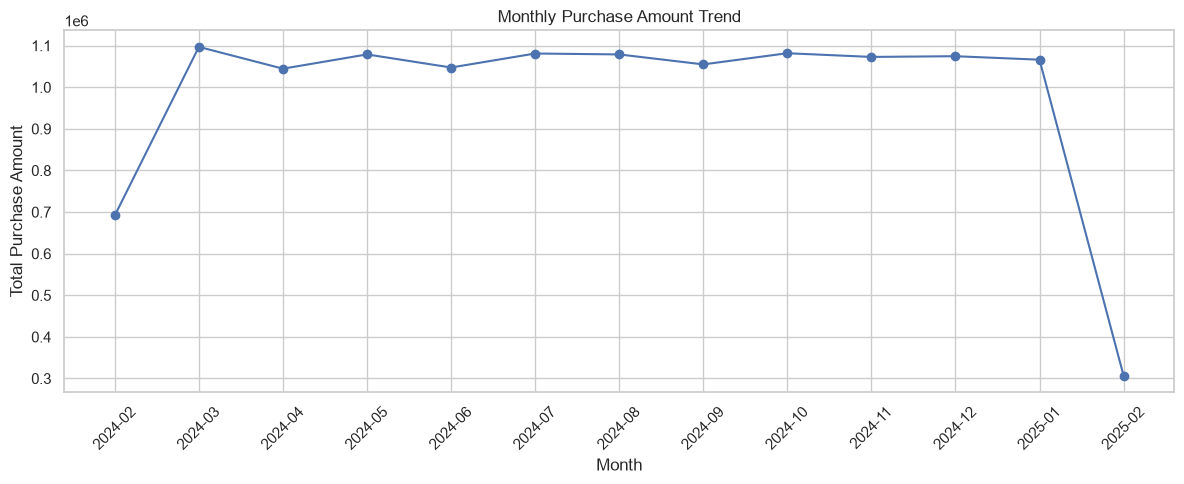

Highest month: 2024-03
Highest total: 1096915.31
Lowest month: 2025-02
Lowest total: 307010.12


In [13]:
monthly_sales = (
    df.groupby("Month")["Purchase_Amount"]
      .sum()
      .sort_index()
)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)
plt.title("Monthly Purchase Amount Trend")
plt.xlabel("Month")
plt.ylabel("Total Purchase Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Highest month:", monthly_sales.idxmax())
print("Highest total:", round(monthly_sales.max(), 2))
print("Lowest month:", monthly_sales.idxmin())
print("Lowest total:", round(monthly_sales.min(), 2))

## 10. Quarterly Purchase Trend Analysis

Quarterly analysis groups purchase amounts into three-month periods. It provides a broader view of purchasing activity than monthly analysis and helps compare different quarters.

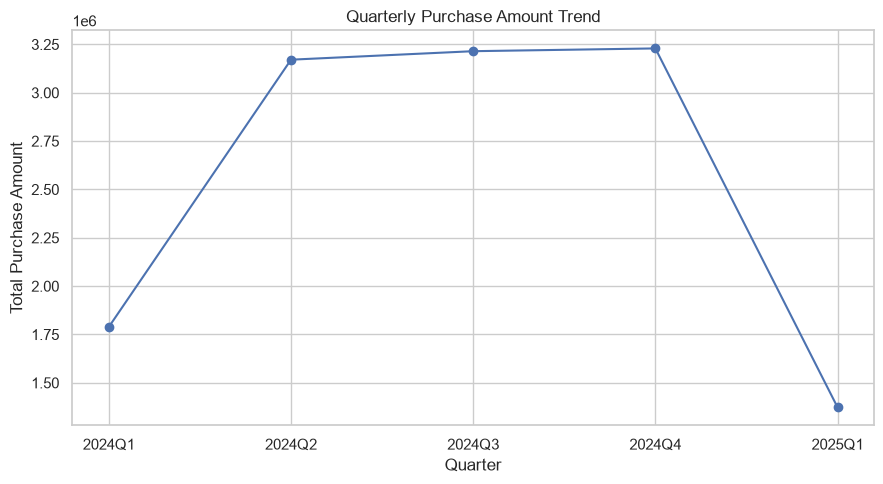

Highest quarter: 2024Q4
Highest quarterly total: 3229081.39
Lowest quarter: 2025Q1
Lowest quarterly total: 1373172.99


In [15]:
quarterly_sales = (
    df.groupby("Quarter")["Purchase_Amount"]
      .sum()
      .sort_index()
)

plt.figure(figsize=(9, 5))
plt.plot(
    quarterly_sales.index.astype(str),
    quarterly_sales.values,
    marker="o"
)
plt.title("Quarterly Purchase Amount Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Purchase Amount")
plt.tight_layout()
plt.show()

print("Highest quarter:", quarterly_sales.idxmax())
print("Highest quarterly total:",
      round(quarterly_sales.max(), 2))
print("Lowest quarter:", quarterly_sales.idxmin())
print("Lowest quarterly total:",
      round(quarterly_sales.min(), 2))

## 11. Customer Demographic Analysis — Age Groups

Customers are grouped by age to understand how purchase records are distributed across age ranges. A bar chart makes it easier to compare the number of records in each group.

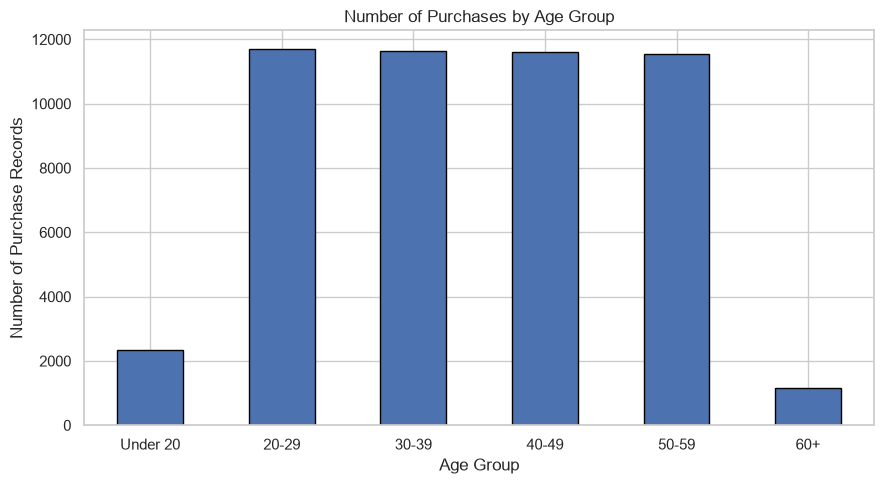

,Number of Purchase Records
Age_Group,
Under 20,2338
20-29,11692
30-39,11646
40-49,11621
50-59,11552
60+,1151


Most represented age group: 20-29
Number of records: 11692


In [16]:
age_counts = df["Age_Group"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
age_counts.plot(kind="bar", edgecolor="black")
plt.title("Number of Purchases by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Purchase Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(age_counts.rename(
    "Number of Purchase Records"
).to_frame())

print("Most represented age group:", age_counts.idxmax())
print("Number of records:", age_counts.max())

## 12. Customer Demographic Analysis — Gender

This analysis compares the proportion of purchase records across the gender categories provided in the dataset. A pie chart displays each category's share of the records.

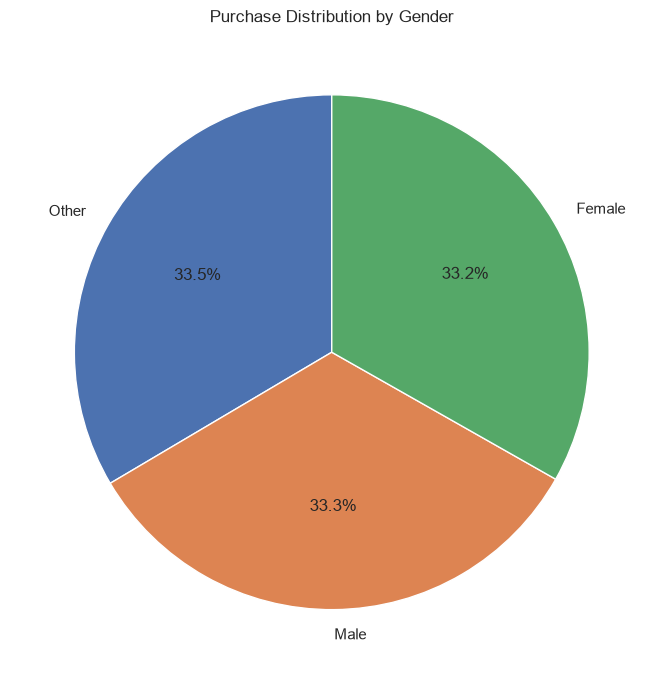

,Number of Purchase Records
Gender,
Other,16751
Male,16644
Female,16605


Most represented category: Other


In [17]:
gender_counts = df["Gender"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Purchase Distribution by Gender")
plt.tight_layout()
plt.show()

display(gender_counts.rename(
    "Number of Purchase Records"
).to_frame())

print("Most represented category:", gender_counts.idxmax())

## 13. Product Performance Analysis — Top 10 Products

This analysis ranks products by total purchase amount and separately examines how frequently each product appears.

The dataset does not contain a quantity-sold column, so the total purchase amount is used as a measure of recorded purchase value rather than units sold.

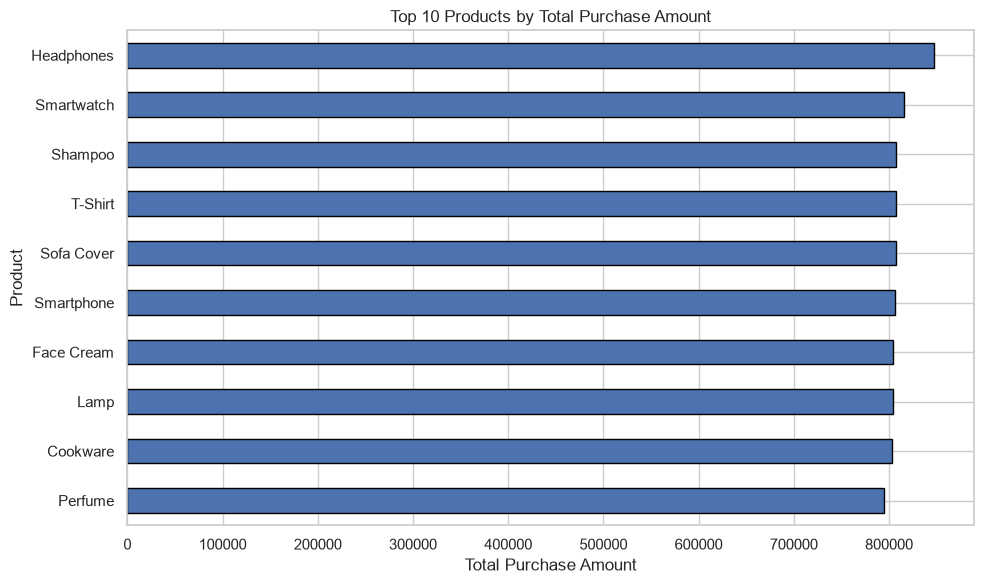

,Total Purchase Amount
Product_Name,
Headphones,846878.56
Smartwatch,815327.06
Shampoo,807428.81
T-Shirt,806845.23
Sofa Cover,806825.96
Smartphone,806437.27
Face Cream,804426.24
Lamp,804282.65
Cookware,802796.26


Top product by purchase amount: Headphones

Most frequently recorded products:


,Number of Purchase Records
Product_Name,
Headphones,3261
T-Shirt,3206
Smartwatch,3177
Face Cream,3174
Sofa Cover,3156
Cookware,3155
Shampoo,3145
Lamp,3138
Perfume,3116


In [18]:
top_products = (
    df.groupby("Product_Name")["Purchase_Amount"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind="barh", edgecolor="black")
plt.title("Top 10 Products by Total Purchase Amount")
plt.xlabel("Total Purchase Amount")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

display(top_products.rename(
    "Total Purchase Amount"
).to_frame())

print("Top product by purchase amount:", top_products.idxmax())

print("\nMost frequently recorded products:")
display(
    df["Product_Name"].value_counts()
      .head(10)
      .rename("Number of Purchase Records")
      .to_frame()
)

## 14. Product Category Analysis

This analysis calculates the total purchase amount for each product category and compares the results using a bar chart.

The results can help identify categories that contribute the largest share of recorded purchase value.

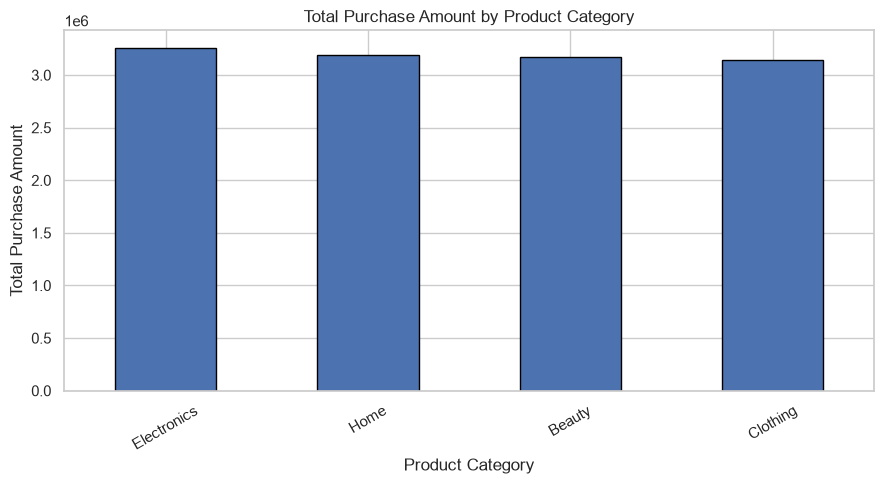

,Total Purchase Amount
Category,
Electronics,3260688.09
Home,3195217.51
Beauty,3174727.90
Clothing,3145977.98


Top category: Electronics
Top category amount: 3260688.09


In [19]:
category_sales = (
    df.groupby("Category")["Purchase_Amount"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
category_sales.plot(kind="bar", edgecolor="black")
plt.title("Total Purchase Amount by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Purchase Amount")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(category_sales.rename(
    "Total Purchase Amount"
).to_frame())

print("Top category:", category_sales.idxmax())
print("Top category amount:",
      round(category_sales.max(), 2))

## 15. Correlation Analysis

A correlation heatmap visualizes the relationships between numerical variables.

This analysis examines customer age, purchase amount, and rating to see whether any pairs of variables have positive or negative linear relationships.

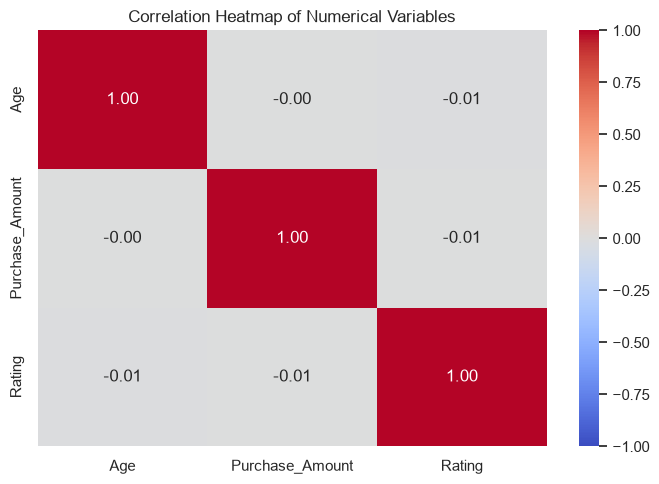

,Age,Purchase_Amount,Rating
Age,1.00,-0.00,-0.01
Purchase_Amount,-0.00,1.00,-0.01
Rating,-0.01,-0.01,1.00


In [20]:
correlation_data = df[
    ["Age", "Purchase_Amount", "Rating"]
]

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

display(correlation_matrix.round(2))

## 16. Additional Analysis — Repeat Customer Behavior

This analysis compares the average purchase amount for repeat customers and non-repeat customers.

It helps investigate whether the two groups differ in their average recorded purchase amounts and whether customer retention strategies deserve further evaluation.

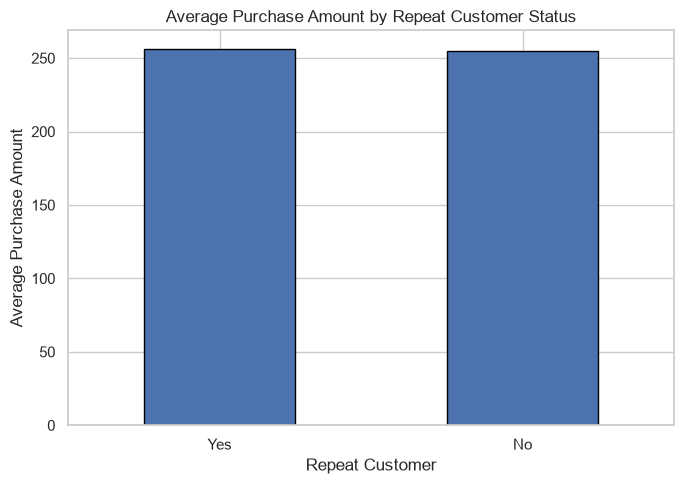

,Average Purchase Amount
Repeat_Customer,
Yes,256.01
No,255.04


Difference (repeat minus non-repeat): 0.97
Repeat customers have the higher average purchase amount.


In [21]:
repeat_spending = (
    df.groupby("Repeat_Customer")["Purchase_Amount"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(7, 5))
repeat_spending.plot(kind="bar", edgecolor="black")
plt.title("Average Purchase Amount by Repeat Customer Status")
plt.xlabel("Repeat Customer")
plt.ylabel("Average Purchase Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(repeat_spending.rename(
    "Average Purchase Amount"
).to_frame())

if "Yes" in repeat_spending.index and "No" in repeat_spending.index:
    difference = repeat_spending["Yes"] - repeat_spending["No"]
    print("Difference (repeat minus non-repeat):",
          round(difference, 2))

    if difference > 0:
        print("Repeat customers have the higher average purchase amount.")
    elif difference < 0:
        print("Non-repeat customers have the higher average purchase amount.")
    else:
        print("Both groups have the same average purchase amount.")

## 17. Discount Analysis

This analysis compares purchase amounts for transactions with and without a discount. It helps explore how purchase values differ according to discount status.

,count,mean,median,sum
Discount_Applied,,,,
No,25018,255.49,255.00,6391824.13
Yes,24982,255.58,255.08,6384787.35


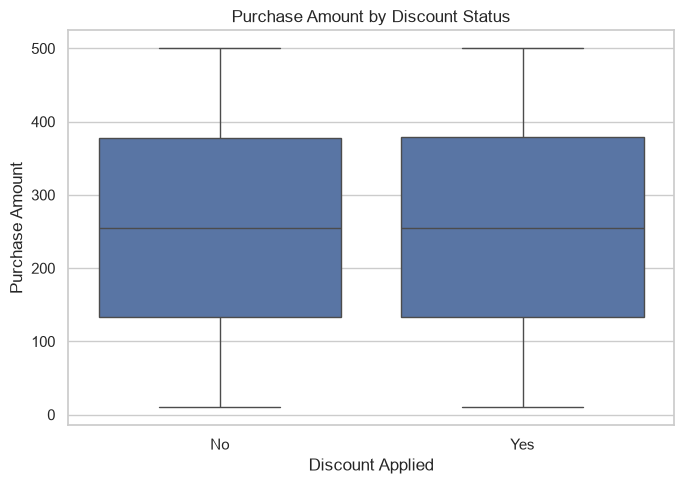

In [22]:
discount_summary = (
    df.groupby("Discount_Applied")["Purchase_Amount"]
      .agg(["count", "mean", "median", "sum"])
      .round(2)
)

display(discount_summary)

plt.figure(figsize=(7, 5))
sns.boxplot(
    data=df,
    x="Discount_Applied",
    y="Purchase_Amount"
)
plt.title("Purchase Amount by Discount Status")
plt.xlabel("Discount Applied")
plt.ylabel("Purchase Amount")
plt.tight_layout()
plt.show()

## 18. Overall Summary of Key Findings

This section brings together the main numerical results from the analysis, including total purchase amount, average purchase amount, monthly and quarterly trends, customer demographics, product performance, category performance, and repeat-customer behavior.

In [23]:
print("=" * 55)
print("RETAIL PURCHASE EDA — KEY FINDINGS")
print("=" * 55)

print("Total records:", len(df))
print("Total purchase amount:",
      round(df["Purchase_Amount"].sum(), 2))
print("Average purchase amount:",
      round(df["Purchase_Amount"].mean(), 2))
print("Median purchase amount:",
      round(df["Purchase_Amount"].median(), 2))
print("Average customer age:", round(df["Age"].mean(), 2))
print("Average rating:", round(df["Rating"].mean(), 2))

print("\nTime Trends")
print("Highest purchase month:", monthly_sales.idxmax())
print("Highest purchase quarter:", quarterly_sales.idxmax())

print("\nCustomer Demographics")
print("Most represented age group:", age_counts.idxmax())
print("Most represented gender category:", gender_counts.idxmax())

print("\nProduct Performance")
print("Top product by purchase amount:", top_products.idxmax())
print("Top category by purchase amount:", category_sales.idxmax())

print("\nRepeat Customer Comparison")
display(repeat_spending.rename(
    "Average Purchase Amount"
).to_frame())

print("\nCategory Summary")
display(category_sales.rename(
    "Total Purchase Amount"
).to_frame())

RETAIL PURCHASE EDA — KEY FINDINGS
Total records: 50000
Total purchase amount: 12776611.48
Average purchase amount: 255.53
Median purchase amount: 255.04
Average customer age: 38.95
Average rating: 3.0

Time Trends
Highest purchase month: 2024-03
Highest purchase quarter: 2024Q4

Customer Demographics
Most represented age group: 20-29
Most represented gender category: Other

Product Performance
Top product by purchase amount: Headphones
Top category by purchase amount: Electronics

Repeat Customer Comparison


,Average Purchase Amount
Repeat_Customer,
Yes,256.01
No,255.04



Category Summary


,Total Purchase Amount
Category,
Electronics,3260688.09
Home,3195217.51
Beauty,3174727.90
Clothing,3145977.98


## 19. Conclusion

Exploratory Data Analysis was performed on the Walmart Customer Purchases dataset using Python, Pandas, NumPy, Matplotlib, and Seaborn.

The analysis examined the dataset's structure and data quality, calculated descriptive statistics, explored monthly and quarterly purchase trends, and analyzed customer demographics, product performance, and category-level purchase amounts.

A correlation heatmap was used to examine relationships between numerical variables. Additional analysis compared average purchase amounts by repeat-customer status and discount status.

The results provide a structured overview of recorded purchasing activity and help identify areas for further business investigation. Since the dataset does not include product costs, profit, or quantity sold, the findings describe purchase values and transaction patterns rather than profitability or exact units sold.

Overall, this project demonstrates how data analysis and visualization can support evidence-based retail decisions.

## 20. Actionable Business Recommendations

1. **Inventory planning:** Review the products and categories with the highest total purchase amounts. Use stock-level and quantity-sold data to validate inventory decisions.

2. **Sales planning:** Investigate months and quarters with comparatively low purchase amounts. Test targeted promotions and measure whether they improve subsequent results.

3. **Customer retention:** Compare repeat and non-repeat customer behavior. Test loyalty programs or personalized offers and measure repeat-purchase rates over time.

4. **Discount optimization:** Compare discounted and non-discounted transactions, then evaluate future discount campaigns using incremental sales and profit measures.

5. **Customer-focused marketing:** Use demographic patterns as a starting point for understanding the customer base. Validate these patterns against additional customer data before making major marketing decisions.

6. **Improve future analysis:** Collect quantity sold, product cost, profit, and transaction-level identifiers so future analysis can measure units sold, profitability, and customer purchasing frequency more accurately.

## 21. Exporting the Prepared Dataset

The cleaned dataset is saved as a separate CSV file for future analysis. The original dataset remains unchanged.

In [24]:
df.to_csv(
    "data/cleaned_walmart_customer_purchases.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!
